# 09 · Percepción de la plataforma después de usarla (n = 50)

Encuesta aplicada el 9 de octubre de 2026 a personas que probaron el prototipo de WELLTUR. Mide **aceptación percibida** (facilidad, claridad, ajuste, satisfacción, intención de uso).
No tiene identificadores para unirla con la encuesta de estrés ni registra qué lugar vio cada persona, así que **no entrena el modelo**: complementa la evaluación offline (notebooks 05 y 08) con la opinión de usuarios.

Se reporta el % de respuestas 4–5 ("top-2") con IC 95 % de Wilson, la fiabilidad y un análisis de sensibilidad sin las respuestas en línea recta (todas iguales), que suelen inflar los resultados.

In [1]:
import sys
from pathlib import Path
SRC = next(p for p in [Path('src'), Path('../src'), Path('MODELO/src')] if (p / 'encuesta_etl.py').exists()).resolve()
sys.path.insert(0, str(SRC))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from lab_graficas import aplicar_estilo, guardar, TEXTO_2
aplicar_estilo()
crudo = pd.read_csv(SRC.parent / 'data' / 'encuesta' / 'raw' / 'percepcion_welltur_2026.csv', encoding='utf-8-sig')
CORTOS = ['Facilidad de uso', 'Claridad de la información', 'Ajuste a mis necesidades de descanso',
          'Descubrir experiencias nuevas', 'Interés en turismo de bienestar', 'Cambio de percepción (P6)',
          'Conocer lugares locales que desconocía', 'Disposición a destinos menos masificados',
          'Satisfacción general', 'Volvería a usarla']
p = crudo.iloc[:, 1:].copy(); p.columns = CORTOS
P6 = {'Disminuyó considerablemente': 1, 'Disminuyó ligeramente': 2, 'No cambió': 3, 'Aumentó ligeramente': 4, 'Aumentó considerablemente': 5}
p['Cambio de percepción (P6)'] = p['Cambio de percepción (P6)'].str.strip().map(P6)
p = p.astype(int)
likert = [c for c in CORTOS if c != 'Cambio de percepción (P6)']
linea_recta = p[likert].nunique(axis=1) == 1
print('respuestas:', len(p), '| en línea recta (mismo valor en los 9 ítems):', int(linea_recta.sum()))

respuestas: 50 | en línea recta (mismo valor en los 9 ítems): 20


In [2]:
def alfa(df):
    k = df.shape[1]; return k / (k - 1) * (1 - df.var(ddof=1).sum() / df.sum(axis=1).var(ddof=1))
def wilson(x, n, z=1.96):
    ph = x / n; centro = (ph + z**2 / (2 * n)) / (1 + z**2 / n)
    margen = z * np.sqrt(ph * (1 - ph) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centro - margen, centro + margen
filas = []
for c in CORTOS:
    for grupo, datos in [('todas', p[c]), ('sin línea recta', p.loc[~linea_recta, c])]:
        x, n = int((datos >= 4).sum()), len(datos); lo, hi = wilson(x, n)
        filas.append({'ítem': c, 'grupo': grupo, 'n': n, 'top2_%': round(100 * x / n, 1), 'IC95': f'{100*lo:.0f}–{100*hi:.0f}', 'media': round(datos.mean(), 2)})
tabla = pd.DataFrame(filas).pivot(index='ítem', columns='grupo', values=['top2_%', 'IC95', 'media']).reindex(CORTOS)
print('alfa de Cronbach (9 ítems Likert):', round(alfa(p[likert]), 3))
tabla

alfa de Cronbach (9 ítems Likert): 0.899


top2_%        \
grupo                                    sin línea recta todas   
ítem                                                             
Facilidad de uso                                    76.7  86.0   
Claridad de la información                          93.3  96.0   
Ajuste a mis necesidades de descanso                80.0  88.0   
Descubrir experiencias nuevas                       83.3  90.0   
Interés en turismo de bienestar                     80.0  88.0   
Cambio de percepción (P6)                           83.3  80.0   
Conocer lugares locales que desconocía              86.7  92.0   
Disposición a destinos menos masificados            93.3  96.0   
Satisfacción general                                93.3  96.0   
Volvería a usarla                                   90.0  94.0   

                                                    IC95         \
grupo                                    sin línea recta  todas   
ítem                                                              
Facilidad de uso                                   59–88  74–93   
Claridad de la información                         79–98  87–99   
Ajuste a mis necesidades de descanso               63–90  76–94   
Descubrir experiencias nuevas                      66–93  79–96   
Interés en turismo de bienestar                    63–90  76–94   
Cambio de percepción (P6)                          66–93  67–89   
Conocer lugares locales que desconocía             70–95  81–97   
Disposición a destinos menos masificados           79–98  87–99   
Satisfacción general                               79–98  87–99   
Volvería a usarla                                  74–97  84–98   

                                                   media        
grupo                                    sin línea recta todas  
ítem                                                            
Facilidad de uso                                    4.33   4.6  
Claridad de la información                          4.47  4.68  
Ajuste a mis necesidades de descanso                3.97  4.38  
Descubrir experiencias nuevas                       4.37  4.62  
Interés en turismo de bienestar                     4.27  4.56  
Cambio de percepción (P6)                           4.17   4.1  
Conocer lugares locales que desconocía              4.37  4.62  
Disposición a destinos menos masificados            4.37  4.62  
Satisfacción general                                 4.6  4.76  
Volvería a usarla                                   4.47  4.68

## Distribución de respuestas (Likert divergente)

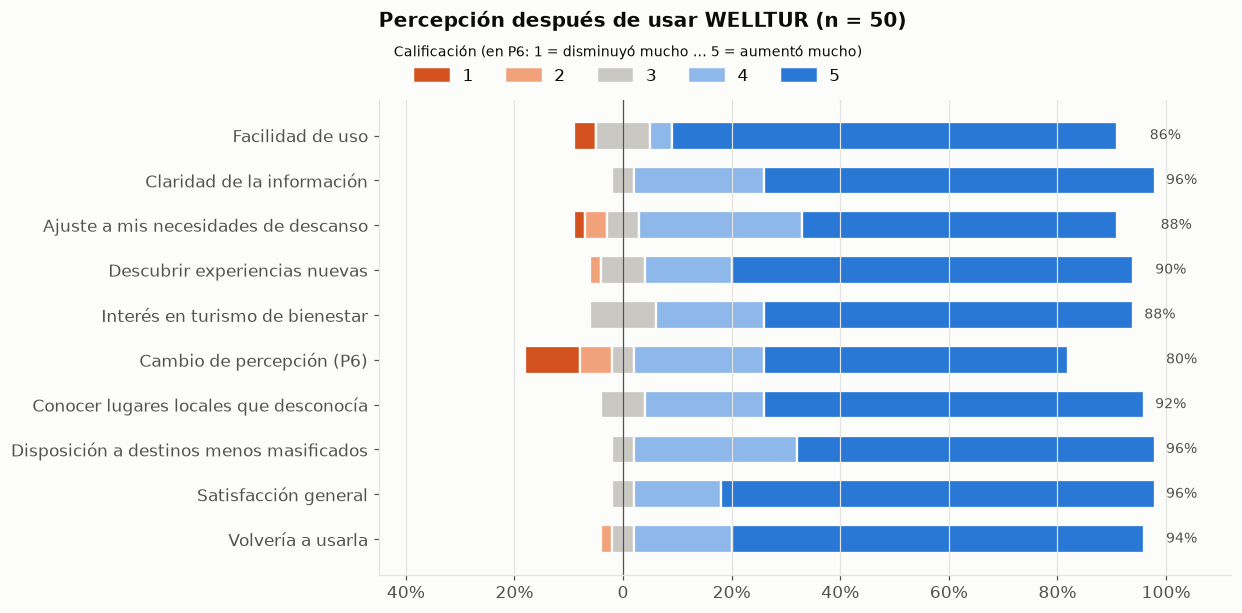

In [3]:
NEG2, NEG1, NEU, POS1, POS2 = '#d4521f', '#f2a27a', '#c9c8c3', '#8fb8ea', '#2a78d6'
orden = list(reversed(CORTOS))
fig, ax = plt.subplots(figsize=(10, 5.6))
for i, c in enumerate(orden):
    frac = p[c].value_counts(normalize=True).reindex([1, 2, 3, 4, 5], fill_value=0).to_numpy() * 100
    izquierda = -(frac[0] + frac[1] + frac[2] / 2)
    for valor, color in zip(frac, [NEG2, NEG1, NEU, POS1, POS2]):
        ax.barh(i, valor, left=izquierda, color=color, height=0.62, edgecolor='#fcfcfb', linewidth=1.5)
        izquierda += valor
    ax.text(102 - frac[2] / 2, i, f'{frac[3] + frac[4]:.0f}%', va='center', color=TEXTO_2, fontsize=9)
ax.axvline(0, color=TEXTO_2, linewidth=0.8)
ax.set_yticks(range(len(orden)), orden); ax.set_xlim(-45, 112)
ax.set_xticks([-40, -20, 0, 20, 40, 60, 80, 100], ['40%', '20%', '0', '20%', '40%', '60%', '80%', '100%'])
ax.grid(axis='y', visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=l) for c, l in zip([NEG2, NEG1, NEU, POS1, POS2], ['1', '2', '3', '4', '5'])],
          frameon=False, ncols=5, loc='lower left', bbox_to_anchor=(0, 1.0), title='Calificación (en P6: 1 = disminuyó mucho … 5 = aumentó mucho)', title_fontsize=9)
ax.set_title('Percepción después de usar WELLTUR (n = 50)', pad=48)
guardar(fig, '09_percepcion_likert');

## Cambio de percepción (P6) y respuestas en línea recta

In [4]:
pd.crosstab(p['Cambio de percepción (P6)'].map({v: k for k, v in P6.items()}), linea_recta.map({True: 'línea recta', False: 'variadas'}), margins=True)

col_0,línea recta,variadas,All
Cambio de percepción (P6),,,
Aumentó considerablemente,15,13,28
Aumentó ligeramente,0,12,12
Disminuyó considerablemente,5,0,5
Disminuyó ligeramente,0,3,3
No cambió,0,2,2
All,20,30,50


## Lectura
* **Aceptación alta:** entre 86 % y 96 % califica con 4–5 cada aspecto; el ajuste de las recomendaciones a sus necesidades de descanso obtuvo 88 % (media 4.4/5). La escala es consistente (α ≈ 0.90).
* **Versión conservadora (sin las 20 respuestas en línea recta, n = 30):** los porcentajes bajan pero se sostienen: 77 % facilidad, **80 % ajuste a sus necesidades** (media 4.0), 93 % satisfacción, 90 % volvería a usarla. Conviene citar esta versión en la defensa.
* **Cautela:** muestra de conveniencia del mismo día y sin grupo de comparación; mide percepción, no eficacia.
* **P6 revela un sesgo de respuesta:** las 5 personas que marcaron "disminuyó considerablemente" son personas que calificaron con 5 todo lo demás; lo más probable es que marcaran la misma posición sin leer (P6 tiene opciones de texto, no números). Entre quienes respondieron con variación, 25 de 30 (83 %) dicen que su percepción aumentó y 3 que disminuyó ligeramente.
* Esta encuesta evaluó el **prototipo anterior** (selección de dimensiones). La versión v2 debe evaluarse de nuevo con el mismo cuestionario más la pregunta de qué lugar eligió cada persona, para medir relevancia por lugar.